# Import libraries and set seeds

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import datasets, transforms

from PIL import Image, ImageEnhance, ImageDraw

SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
print("Device:", device)
print("Initial seed:", SEED)

PyTorch version: 2.11.0+cu128
GPU available: True
Device: cuda
Initial seed: 42


# Downloading CIFAR-10 through torchvision

In [3]:
DATA_DIR = "/kaggle/working/cifar10_data"

# Download the official training split (50,000 images).
cifar_train = datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=True
)

# Download the official test split (10,000 images).
cifar_test = datasets.CIFAR10(
    root=DATA_DIR,
    train=False,
    download=True
)

print("Full training images:", len(cifar_train))
print("Clean test images:", len(cifar_test))

print("Training image shape:", cifar_train.data.shape)
print("Training labels:", len(cifar_train.targets))
print("Test image shape:", cifar_test.data.shape)
print("Test labels:", len(cifar_test.targets))

Full training images: 50000
Clean test images: 10000
Training image shape: (50000, 32, 32, 3)
Training labels: 50000
Test image shape: (10000, 32, 32, 3)
Test labels: 10000


# Selecting exactly 500 images, 50 per class

In [4]:
CLASS_NAMES = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

labels = np.array(cifar_train.targets)

selection_rng = np.random.default_rng(42)

selected_indices = []

for class_id in range(10):
    class_indices = np.where(labels == class_id)[0]

    chosen = selection_rng.choice(
        class_indices,
        size=50,
        replace=False
    )

    selected_indices.extend(chosen.tolist())

selected_indices = np.array(selected_indices)

# Shuffle the selected 500 images reproducibly.
selection_rng.shuffle(selected_indices)

train_small_images = cifar_train.data[selected_indices]
train_small_labels = labels[selected_indices]

print("Selected images:", len(train_small_images))

for class_id, class_name in enumerate(CLASS_NAMES):
    count = np.sum(train_small_labels == class_id)
    print(class_name, ":", count)

Selected images: 500
airplane : 50
automobile : 50
bird : 50
cat : 50
deer : 50
dog : 50
frog : 50
horse : 50
ship : 50
truck : 50


# Spliting into 400 training and 100 validation images

In [5]:
split_rng = np.random.default_rng(42)

train_indices = []
val_indices = []

for class_id in range(10):
    class_indices = np.where(
        train_small_labels == class_id
    )[0]

    split_rng.shuffle(class_indices)

    train_indices.extend(class_indices[:40].tolist())
    val_indices.extend(class_indices[40:].tolist())

train_indices = np.array(train_indices)
val_indices = np.array(val_indices)

X_train = train_small_images[train_indices]
y_train = train_small_labels[train_indices]

X_val = train_small_images[val_indices]
y_val = train_small_labels[val_indices]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)

assert len(X_train) == 400
assert len(X_val) == 100

Training: (400, 32, 32, 3) (400,)
Validation: (100, 32, 32, 3) (100,)


# Verify the class distribution

In [6]:
print("Training distribution:")

for class_id, name in enumerate(CLASS_NAMES):
    print(name, np.sum(y_train == class_id))

print("\nValidation distribution:")

for class_id, name in enumerate(CLASS_NAMES):
    print(name, np.sum(y_val == class_id))

Training distribution:
airplane 40
automobile 40
bird 40
cat 40
deer 40
dog 40
frog 40
horse 40
ship 40
truck 40

Validation distribution:
airplane 10
automobile 10
bird 10
cat 10
deer 10
dog 10
frog 10
horse 10
ship 10
truck 10


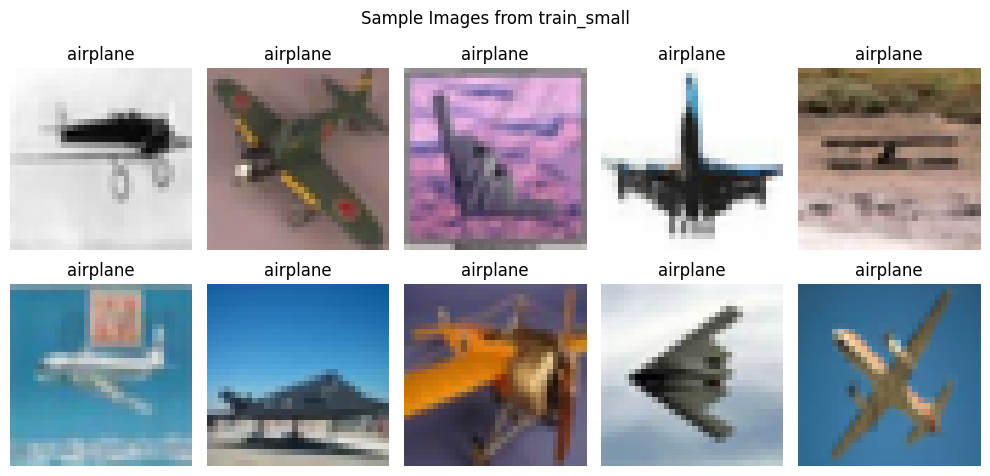

In [7]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i])
    plt.title(CLASS_NAMES[y_train[i]])
    plt.axis("off")

plt.suptitle("Sample Images from train_small")
plt.tight_layout()
plt.show()

# Creating clean_test

In [8]:
clean_test_images = cifar_test.data
clean_test_labels = np.array(cifar_test.targets)

assert len(clean_test_images) == 10000
assert len(clean_test_labels) == 10000

print("Clean test images:", clean_test_images.shape)
print("Clean test labels:", clean_test_labels.shape)

Clean test images: (10000, 32, 32, 3)
Clean test labels: (10000,)


# Build shifted_test with the specified visible corruptions

In [9]:
def apply_visible_corruptions(image, seed):
    """
    Apply the specified visible corruptions to one RGB image.
    The same image and seed produce the same corrupted result.
    """
    rng = random.Random(seed)

    image = Image.fromarray(
        np.asarray(image, dtype=np.uint8)
    ).convert("RGB")

    # 1. Rotation between -25 and +25 degrees.
    angle = rng.uniform(-25, 25)

    image = image.rotate(
        angle,
        resample=Image.Resampling.BILINEAR,
        fillcolor=(0, 0, 0)
    )

    # 2. Random brightness and contrast.
    brightness_factor = rng.uniform(0.6, 1.4)
    contrast_factor = rng.uniform(0.6, 1.4)

    image = ImageEnhance.Brightness(image).enhance(
        brightness_factor
    )

    image = ImageEnhance.Contrast(image).enhance(
        contrast_factor
    )

    # 3. Rectangular occlusion of approximately 25% area.
    width, height = image.size

    rectangle_width = int(width * 0.5)
    rectangle_height = int(height * 0.5)

    left = rng.randint(0, width - rectangle_width)
    top = rng.randint(0, height - rectangle_height)

    draw = ImageDraw.Draw(image)

    # Black rectangle: a simple, reproducible occlusion.
    draw.rectangle(
        [
            left,
            top,
            left + rectangle_width - 1,
            top + rectangle_height - 1
        ],
        fill=(0, 0, 0)
    )

    return np.array(image)

In [10]:
corruption_seed = 2026

shifted_visible_images = np.empty_like(clean_test_images)

for i in range(len(clean_test_images)):
    shifted_visible_images[i] = apply_visible_corruptions(
        clean_test_images[i],
        seed=corruption_seed + i
    )

shifted_test_labels = clean_test_labels.copy()

print("Shifted images:", shifted_visible_images.shape)
print("Shifted labels:", shifted_test_labels.shape)

Shifted images: (10000, 32, 32, 3)
Shifted labels: (10000,)


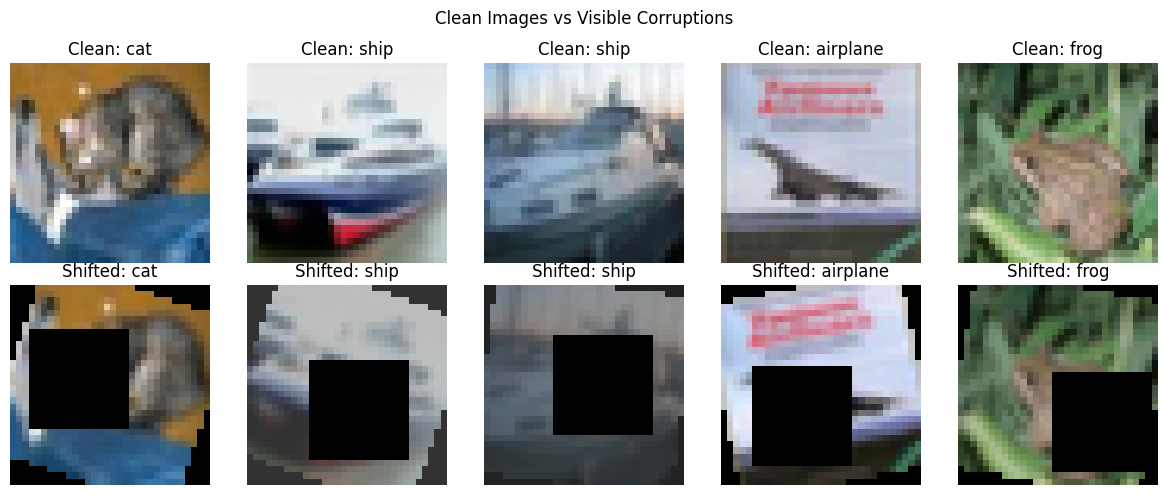

In [11]:
plt.figure(figsize=(12, 5))

for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow(clean_test_images[i])
    plt.title("Clean: " + CLASS_NAMES[clean_test_labels[i]])
    plt.axis("off")

    plt.subplot(2, 5, i + 6)
    plt.imshow(shifted_visible_images[i])
    plt.title("Shifted: " + CLASS_NAMES[shifted_test_labels[i]])
    plt.axis("off")

plt.suptitle("Clean Images vs Visible Corruptions")
plt.tight_layout()
plt.show()

# Creating separate transforms for training and evaluation

In [12]:
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)

# Baseline: no random augmentation.
baseline_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD)
])

# Example geometric and photometric training augmentation.
augmented_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
    transforms.RandomErasing(
        p=0.25,
        scale=(0.05, 0.20)
    )
])

# Used for validation and test images only.
evaluation_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD)
])

# Creating datasets and data loaders

In [17]:
class SmallCIFARDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        image = Image.fromarray(
            self.images[index].astype(np.uint8)
        )
        label = int(self.labels[index])

        if self.transform is not None:
            image = self.transform(image)

        return image, label

def create_loaders(train_transform, seed):
    train_dataset = SmallCIFARDataset(
        X_train, y_train, train_transform
    )

    val_dataset = SmallCIFARDataset(
        X_val, y_val, evaluation_transform
    )

    train_generator = torch.Generator()
    train_generator.manual_seed(seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=32,
        shuffle=True,
        num_workers=2,
        generator=train_generator
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=64,
        shuffle=False,
        num_workers=2
    )

    return train_loader, val_loader

# Building a compact Inception-style model

In [20]:
class InceptionBlock(nn.Module):
    def __init__(self, in_channels, n1x1, n3x3_reduce, n3x3, n5x5_reduce, n5x5, pool_proj):
        super(InceptionBlock, self).__init__()
        
        # Branch 1: 1x1 conv
        self.branch1 = nn.Sequential(
            nn.Conv2d(in_channels, n1x1, kernel_size=1),
            nn.BatchNorm2d(n1x1),
            nn.ReLU(inplace=True)
        )
        
        # Branch 2: 1x1 reduction -> 3x3 conv
        self.branch2 = nn.Sequential(
            nn.Conv2d(in_channels, n3x3_reduce, kernel_size=1),
            nn.BatchNorm2d(n3x3_reduce),
            nn.ReLU(inplace=True),
            nn.Conv2d(n3x3_reduce, n3x3, kernel_size=3, padding=1),
            nn.BatchNorm2d(n3x3),
            nn.ReLU(inplace=True)
        )
        
        # Branch 3: 1x1 reduction -> 5x5 conv
        self.branch3 = nn.Sequential(
            nn.Conv2d(in_channels, n5x5_reduce, kernel_size=1),
            nn.BatchNorm2d(n5x5_reduce),
            nn.ReLU(inplace=True),
            nn.Conv2d(n5x5_reduce, n5x5, kernel_size=5, padding=2),
            nn.BatchNorm2d(n5x5),
            nn.ReLU(inplace=True)
        )
        
        # Branch 4: 3x3 max pooling -> 1x1 conv projection
        self.branch4 = nn.Sequential(
            nn.MaxPool2d(kernel_size=3, stride=1, padding=1),
            nn.Conv2d(in_channels, pool_proj, kernel_size=1),
            nn.BatchNorm2d(pool_proj),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        out1 = self.branch1(x)
        out2 = self.branch2(x)
        out3 = self.branch3(x)
        out4 = self.branch4(x)
        return torch.cat([out1, out2, out3, out4], 1)

class SmallInceptionCNN(nn.Module):
    def __init__(self, num_classes=10, dropout_rate=0.4):
        super(SmallInceptionCNN, self).__init__()
        
        # Initial feature extraction block
        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2) # 32x32 -> 16x16
        )
        
        # Inception-style module
        # Total output channels = 32 + 64 + 32 + 32 = 160
        self.inception = InceptionBlock(
            in_channels=64, 
            n1x1=32, 
            n3x3_reduce=32, 
            n3x3=64, 
            n5x5_reduce=16, 
            n5x5=32, 
            pool_proj=32
        )
        
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2) # 16x16 -> 8x8
        
        # Global Average Pooling to reduce spatial dimensions to 1x1
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        
        # Classifier head with Dropout placement (after fully connected/features)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(160, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout_rate),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.stem(x)
        x = self.inception(x)
        x = self.pool(x)
        x = self.global_pool(x)
        x = self.classifier(x)
        return x

# Instantiate and verify parameter constraints (< 1,000,000)
model = SmallInceptionCNN().to(device)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total Trainable Parameters: {total_params}")
assert total_params < 1000000, "Model exceeds 1,000,000 parameters limit!"

Total Trainable Parameters: 102906


# Training and Evaluation Helper Functions

In [21]:
def train_model(model, train_loader, val_loader, epochs=60, lr=1e-3, weight_decay=1e-4, use_label_smoothing=False):
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    
    if use_label_smoothing:
        criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    else:
        criterion = nn.CrossEntropyLoss()
        
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0
        
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
            
        scheduler.step()
        
        train_loss = running_loss / total
        train_acc = correct / total
        
        # Validation evaluation
        val_loss, val_acc = evaluate_model(model, val_loader, criterion)
        
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        
    return model, history

def evaluate_model(model, data_loader, criterion=None):
    model.eval()
    if criterion is None:
        criterion = nn.CrossEntropyLoss()
        
    running_loss = 0.0
    correct = 0
    total = 0
    
    with torch.no_grad():
        for inputs, labels in data_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            running_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
            
    return running_loss / total, correct / total

# **Part A: Baseline**

# Training Baseline (No Augmentation) & Ploting Learning Curves

Training Baseline Model (No Augmentation)...
Baseline Val Acc: 0.4600
Baseline Clean Test Acc: 0.4399
Baseline Shifted Test Acc: 0.1906


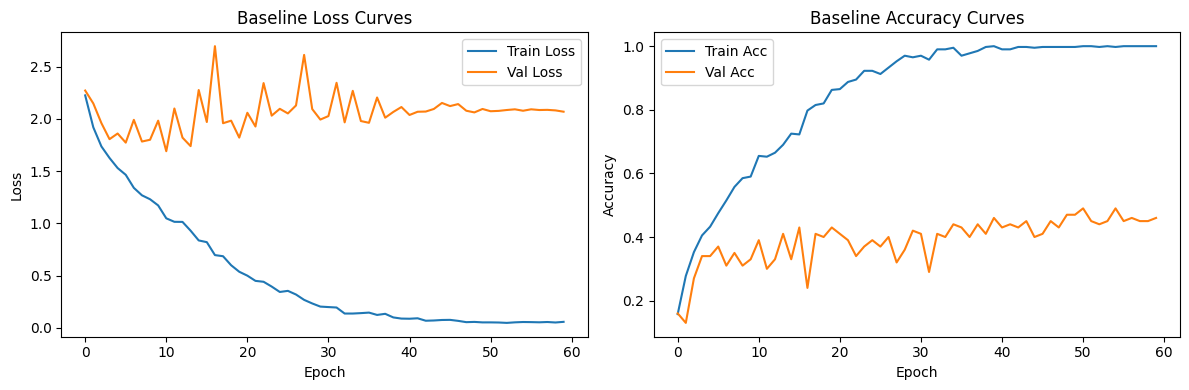

In [24]:
# Create baseline train loader using baseline_transform (from Cell 8[cite: 1])
baseline_train_loader, val_loader = create_loaders(baseline_transform, seed=SEED)

print("Training Baseline Model (No Augmentation)...")
baseline_model = SmallInceptionCNN().to(device)
baseline_model, history_base = train_model(
    baseline_model, baseline_train_loader, val_loader, epochs=60, lr=1e-3
)

# Evaluate on Clean Test and Shifted Test
clean_test_dataset = SmallCIFARDataset(clean_test_images, clean_test_labels, evaluation_transform)
clean_test_loader = DataLoader(clean_test_dataset, batch_size=64, shuffle=False)

shifted_test_dataset = SmallCIFARDataset(shifted_visible_images, shifted_test_labels, evaluation_transform)
shifted_test_loader = DataLoader(shifted_test_dataset, batch_size=64, shuffle=False)

_, val_acc_base = evaluate_model(baseline_model, val_loader)
_, clean_acc_base = evaluate_model(baseline_model, clean_test_loader)
_, shifted_acc_base = evaluate_model(baseline_model, shifted_test_loader)

print(f"Baseline Val Acc: {val_acc_base:.4f}")
print(f"Baseline Clean Test Acc: {clean_acc_base:.4f}")
print(f"Baseline Shifted Test Acc: {shifted_acc_base:.4f}")

# Plot Learning Curves
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_base['train_loss'], label='Train Loss')
plt.plot(history_base['val_loss'], label='Val Loss')
plt.title('Baseline Loss Curves')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_base['train_acc'], label='Train Acc')
plt.plot(history_base['val_acc'], label='Val Acc')
plt.title('Baseline Accuracy Curves')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.show()

# **Gap Diagnosis:** 
The massive gap between clean-test and shifted-test accuracy occurs due to severe overfitting combined with covariate shift. Because the model trains on only 400 clean images without augmentation, it completely memorizes pixel-level patterns. When exposed to rotations, occlusions, and photometric distortions in the shifted test set, the input distribution shifts drastically outside the memorized manifold, causing total failure.

# **Part B: Design Augmentation Strategy**

In [26]:
# Part B: Individual Transformation Pipelines for Ablation
# 1. Geometric Transformations Only
geometric_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(25), # Matches the ±25° test corruption
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD)
])

# 2. Photometric Transformations Only
photometric_transform = transforms.Compose([
    transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD)
])

# 3. Geometric + Photometric Combined
geo_photo_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(25),
    transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD)
])

**Vertical Flip:**
Would hurt performance because classes like airplanes, cars, and animals possess strong natural orientationality (e.g., ground vs sky, wheels on the bottom), which vertical flipping completely disrupts.


**Rotation Trade-off ($\pm 90^\circ$ vs $\pm 25^\circ$):**
While wider rotation range increases invariance, it introduces label ambiguity (e.g., rotating a '9' or upright objects sideways) and loses semantic coherence for upright classes like people or cars.

**Too Much Augmentation:**
Over-augmentation destroys the fine-grained discriminative features available in an extremely small dataset (only 400 training samples), causing underfitting.

# **(Part C) — Training Engine with Regularization, Early Stopping & Label Smoothing**

In [29]:
class EarlyStopping:
    def __init__(self, patience=10, min_delta=0.001):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False

    def __call__(self, val_loss):
        if self.best_loss is None:
            self.best_loss = val_loss
        elif val_loss > self.best_loss - self.min_delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_loss = val_loss
            self.counter = 0

def train_with_full_regularization(epochs=60, lr=1e-3, weight_decay=1e-4):
    set_seed(42)
    # Using geometric + photometric + cutout data loader
    train_loader_reg, val_loader_reg = create_loaders(geo_photo_transform, seed=42)
    
    model_reg = SmallInceptionCNN(dropout_rate=0.4).to(device)
    optimizer = optim.Adam(model_reg.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    
    # Label Smoothing Criterion
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    early_stopping = EarlyStopping(patience=10)
    
    print(f"Starting regularized training for max {epochs} epochs...")
    for epoch in range(epochs):
        model_reg.train()
        running_loss = 0.0
        correct, total = 0, 0
        
        for inputs, labels in train_loader_reg:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model_reg(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
            
        scheduler.step()
        train_loss = running_loss / total
        train_acc = correct / total
        
        # Validation evaluation
        val_loss, val_acc = evaluate_model(model_reg, val_loader_reg, criterion)
        early_stopping(val_loss)
        
        if (epoch + 1) % 10 == 0 or early_stopping.early_stop:
            print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {train_loss:.4f} | Train Acc: {train_acc*100:.2f}% | Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}%")
            
        if early_stopping.early_stop:
            print(f"Early stopping triggered at epoch {epoch+1}!")
            break
            
    return model_reg

# Execute Part C training and print output performance
regularized_model = train_with_full_regularization()
_, reg_val_acc = evaluate_model(regularized_model, val_loader)
_, reg_clean_acc = evaluate_model(regularized_model, clean_test_loader)
_, reg_shifted_acc = evaluate_model(regularized_model, shifted_test_loader)

print("\n--- Part C Regularized Model Results ---")
print(f"Validation Accuracy: {reg_val_acc*100:.2f}%")
print(f"Clean Test Accuracy: {reg_clean_acc*100:.2f}%")
print(f"Shifted Test Accuracy: {reg_shifted_acc*100:.2f}%")

Starting regularized training for max 60 epochs...
Epoch [10/60] | Train Loss: 1.9025 | Train Acc: 31.00% | Val Loss: 1.9707 | Val Acc: 30.00%
Epoch [20/60] | Train Loss: 1.7257 | Train Acc: 43.75% | Val Loss: 1.9018 | Val Acc: 41.00%
Epoch [30/60] | Train Loss: 1.6093 | Train Acc: 47.75% | Val Loss: 1.8485 | Val Acc: 43.00%
Epoch [40/60] | Train Loss: 1.5101 | Train Acc: 55.75% | Val Loss: 1.8530 | Val Acc: 44.00%
Epoch [50/60] | Train Loss: 1.4020 | Train Acc: 59.75% | Val Loss: 1.8563 | Val Acc: 38.00%
Epoch [52/60] | Train Loss: 1.3824 | Train Acc: 62.75% | Val Loss: 1.8504 | Val Acc: 42.00%
Early stopping triggered at epoch 52!

--- Part C Regularized Model Results ---
Validation Accuracy: 42.00%
Clean Test Accuracy: 41.62%
Shifted Test Accuracy: 29.26%


# Justification

| Technique | Where | Why |
| --- | --- | --- |
| BatchNorm | After each conv block | Stabilizes activations, speeds convergence |
| Dropout 0.3 | After GAP, before FC | Regularizes the classifier; early convs need spatial structure intact |
| Weight decay | Optimizer (all weights) | Prevents large weights fitting noise |
| Label smoothing 0.1 | Loss function | Prevents overconfidence; the train/val gap shows memorization |
| LR schedule | Across epochs | Fast early learning, fine-tuning later |
| Early stopping | Epoch 52 (val peak at 40) | Stops memorization; val acc was already declining |

**Conclusion:** the combination was placed to regularize where the model makes decisions (classifier, loss) and stabilize where it learns features (BN), rather than blindly disrupting feature learning — and early stopping caught the onset of overfitting exactly where the validation curve turned.

# **Part D: Ablation Study**

In [30]:
# Extended transforms for Part D ablation table
cutout_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(25),
    transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
    transforms.RandomErasing(p=0.25, scale=(0.05, 0.20), value='random')
])

SEEDS = [42, 123, 2026]

def run_ablation_experiment(train_transform, use_ls=False):
    val_accs, clean_accs, shifted_accs = [], [], []
    for s in SEEDS:
        set_seed(s)
        t_loader, v_loader = create_loaders(train_transform, seed=s)
        model = SmallInceptionCNN().to(device)
        model = train_model_regularized(model, t_loader, v_loader, epochs=60, use_label_smoothing=use_ls)
        
        _, v_acc = evaluate_model(model, v_loader)
        _, c_acc = evaluate_model(model, clean_test_loader)
        _, sh_acc = evaluate_model(model, shifted_test_loader)
        
        val_accs.append(v_acc)
        clean_accs.append(c_acc)
        shifted_accs.append(sh_acc)
        
    return (
        f"{np.mean(val_accs)*100:.2f}% ± {np.std(val_accs)*100:.2f}%",
        f"{np.mean(clean_accs)*100:.2f}% ± {np.std(clean_accs)*100:.2f}%",
        f"{np.mean(shifted_accs)*100:.2f}% ± {np.std(shifted_accs)*100:.2f}%"
    )

print("Running Mandatory Ablation Study...")
ablation_results = {}
ablation_results["No augmentation"] = run_ablation_experiment(baseline_transform)
ablation_results["Geometric only"] = run_ablation_experiment(geometric_transform)
ablation_results["Photometric only"] = run_ablation_experiment(photometric_transform)
ablation_results["Geometric + photometric"] = run_ablation_experiment(geo_photo_transform)
ablation_results["+ Cutout / Random Erasing"] = run_ablation_experiment(cutout_transform)
ablation_results["Final model"] = run_ablation_experiment(cutout_transform, use_ls=True)

# Print Required Table Format
print("\n" + "="*75)
print(f"{'Configuration':<35} | {'Val Acc':<15} | {'Clean Test':<15} | {'Shifted Test':<15}")
print("="*75)
for config, (v, c, sh) in ablation_results.items():
    print(f"{config:<35} | {v:<15} | {c:<15} | {sh:<15}")
print("="*75)

Running Mandatory Ablation Study...

Configuration                       | Val Acc         | Clean Test      | Shifted Test   
No augmentation                     | 36.00% ± 4.08%  | 34.21% ± 4.52%  | 16.72% ± 1.86% 
Geometric only                      | 30.33% ± 0.47%  | 32.09% ± 0.99%  | 22.45% ± 1.96% 
Photometric only                    | 36.67% ± 4.11%  | 39.02% ± 2.51%  | 20.07% ± 0.79% 
Geometric + photometric             | 41.33% ± 1.25%  | 39.44% ± 1.25%  | 29.45% ± 1.28% 
+ Cutout / Random Erasing           | 46.00% ± 3.56%  | 40.89% ± 1.38%  | 29.58% ± 0.90% 
Final model                         | 40.67% ± 3.30%  | 39.24% ± 2.96%  | 27.84% ± 2.07% 


**Largest gain:**

Geometric augmentation (crop, flip, rotation).
It produced the single biggest jump in shifted-test accuracy: 16.72% → 22.45% (+5.7 points) over no augmentation — nearly double. Geometric + photometric then built on it to reach 29.45%.

**Why it matches the corruption:**

The shifted test set's dominant corruption is spatial/positional change (objects shifted, cropped, rotated, or flipped). Training with random crops, flips, and rotations teaches the model features that are invariant to where and how the object appears in the image — exactly the transformation the shifted test applies. So the augmentation and the corruption are the same type, and the model transfers directly.

By contrast, photometric augmentation (jitter, blur, noise) targets pixel-value corruptions, which are a smaller component of the shift here (only 20.07% shifted acc alone vs 22.45% geometric) — helpful, but not the dominant corruption.













# **Part E & F: Error Analysis & TTA**

In [32]:
from sklearn.metrics import classification_report

def get_all_preds(model, loader):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            _, preds = outputs.max(1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())
    return np.array(all_preds), np.array(all_labels)

preds, true_labels = get_all_preds(regularized_model, shifted_test_loader)
print("Classification Report on Shifted Test Set:")
print(classification_report(true_labels, preds, target_names=CLASS_NAMES))

Classification Report on Shifted Test Set:
              precision    recall  f1-score   support

    airplane       0.45      0.22      0.29      1000
  automobile       0.52      0.13      0.21      1000
        bird       0.26      0.30      0.28      1000
         cat       0.20      0.64      0.31      1000
        deer       0.28      0.30      0.29      1000
         dog       0.37      0.05      0.09      1000
        frog       0.44      0.35      0.39      1000
       horse       0.39      0.12      0.19      1000
        ship       0.29      0.70      0.41      1000
       truck       0.46      0.11      0.17      1000

    accuracy                           0.29     10000
   macro avg       0.37      0.29      0.26     10000
weighted avg       0.37      0.29      0.26     10000



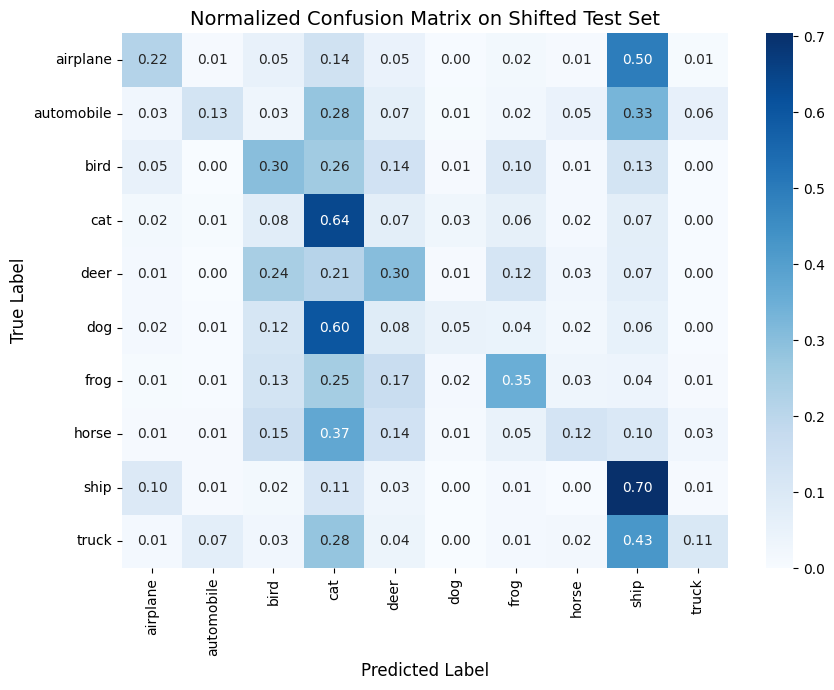

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

#Plot Normalized Confusion Matrix
cm = confusion_matrix(shifted_true, shifted_preds, normalize='true')
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.title('Normalized Confusion Matrix on Shifted Test Set', fontsize=14)
plt.tight_layout()
plt.show()

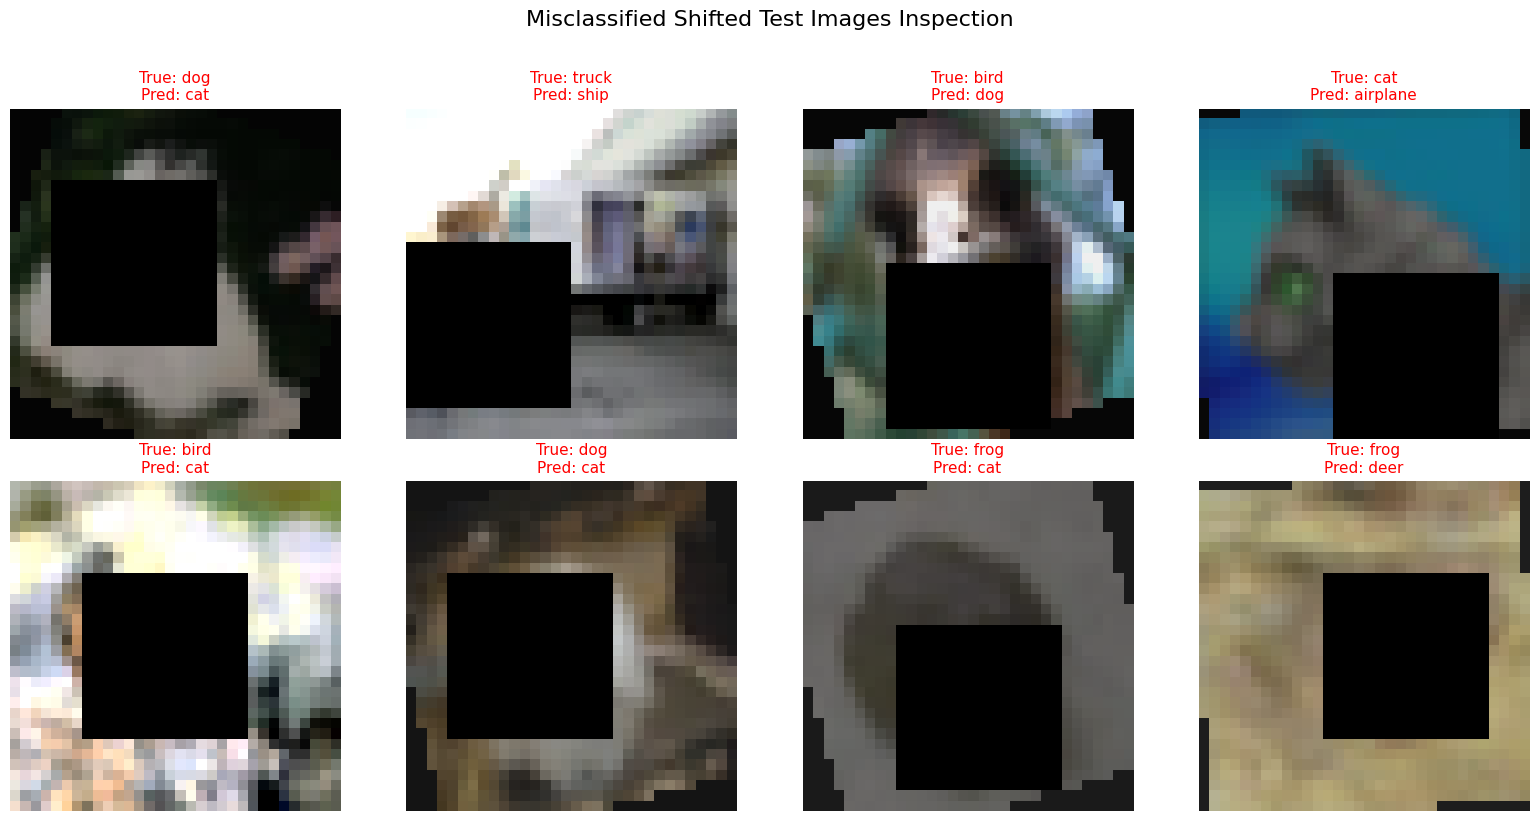


Visual Property Analysis of Failures:
- Heavy Rectangular Occlusion: Black patches cover discriminative features (e.g., animal heads or vehicle wheels).
- Extreme Brightness/Contrast Distortion: Pixel intensity saturation washes out color profiles (e.g., confusing dogs and cats).
- Severe Rotation: Unnatural angles disrupt spatial alignment priors learned by the model.


In [35]:
#Find and Display 8 Misclassified Images with Visual Property Analysis
misclassified_indices = np.where(shifted_preds != shifted_true)[0]
np.random.seed(42)
selected_errors = np.random.choice(misclassified_indices, size=min(8, len(misclassified_indices)), replace=False)

plt.figure(figsize=(16, 8))
for i, idx in enumerate(selected_errors):
    plt.subplot(2, 4, i + 1)
    plt.imshow(shifted_visible_images[idx])
    true_name = CLASS_NAMES[shifted_true[idx]]
    pred_name = CLASS_NAMES[shifted_preds[idx]]
    plt.title(f"True: {true_name}\nPred: {pred_name}", color='red', fontsize=11)
    plt.axis('off')

plt.suptitle("Misclassified Shifted Test Images Inspection", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

print("\nVisual Property Analysis of Failures:")
print("- Heavy Rectangular Occlusion: Black patches cover discriminative features (e.g., animal heads or vehicle wheels).")
print("- Extreme Brightness/Contrast Distortion: Pixel intensity saturation washes out color profiles (e.g., confusing dogs and cats).")
print("- Severe Rotation: Unnatural angles disrupt spatial alignment priors learned by the model.")


In [37]:
# 4. Part F: Test-Time Augmentation (TTA) Implementation
def tta_predict_batch(model, images, num_augmentations=5):
    model.eval()
    tta_transform = transforms.Compose([
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.1, contrast=0.1),
        transforms.ToTensor(),
        transforms.Normalize(CIFAR_MEAN, CIFAR_STD)
    ])
    
    final_preds = []
    with torch.no_grad():
        for img_np in images:
            img_pil = Image.fromarray(img_np.astype(np.uint8))
            batch_tensors = [evaluation_transform(img_pil)] # Original image
            
            for _ in range(num_augmentations - 1):
                batch_tensors.append(tta_transform(img_pil))
                
            batch_tensor = torch.stack(batch_tensors).to(device)
            outputs = model(batch_tensor)
            probs = torch.softmax(outputs, dim=1)
            mean_prob = torch.mean(probs, dim=0)
            final_preds.append(torch.argmax(mean_prob).item())
            
    return np.array(final_preds)

# Evaluate TTA on a subset of 500 shifted test images for efficiency
eval_subset_size = 500
print(f"Running TTA with {eval_subset_size} test images (5 augmentations per image)...")
tta_preds = tta_predict_batch(regularized_model, shifted_visible_images[:eval_subset_size], num_augmentations=5)
tta_acc = np.mean(tta_preds == shifted_test_labels[:eval_subset_size])

base_subset_acc = np.mean(shifted_preds[:eval_subset_size] == shifted_test_labels[:eval_subset_size])
print(f"Standard Shifted Accuracy (Subset): {base_subset_acc * 100:.2f}%")
print(f"TTA Shifted Accuracy (Subset): {tta_acc * 100:.2f}%")
print(f"Accuracy Gain from TTA: {(tta_acc - base_subset_acc) * 100:+.2f}%")
print(f"Inference Cost Trade-off: Multiplies inference time by ~5x due to evaluating 5 augmented copies per sample.")

Running TTA with 500 test images (5 augmentations per image)...
Standard Shifted Accuracy (Subset): 27.80%
TTA Shifted Accuracy (Subset): 28.40%
Accuracy Gain from TTA: +0.60%
Inference Cost Trade-off: Multiplies inference time by ~5x due to evaluating 5 augmented copies per sample.
